# 📊 ChurnShield AI — Análise Exploratória de Dados (EDA)

**Objetivo:** Entender a distribuição dos dados, identificar padrões e relações entre variáveis que influenciam o churn de clientes.

**Etapas:**
1. Carregamento e inspeção inicial dos dados
2. Análise univariada
3. Análise bivariada (features vs churn)
4. Matriz de correlação
5. Insights e conclusões

In [1]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src.data.data_loader import ChurnDataLoader

sns.set_theme(style='whitegrid', palette='husl')
plt.rcParams['figure.figsize'] = (12, 6)
pd.set_option('display.max_columns', None)

print('✅ Bibliotecas carregadas!')

✅ Bibliotecas carregadas!


## 1. Carregamento dos Dados

In [2]:
loader = ChurnDataLoader()
df = loader.load(use_synthetic=True)

print(f'Shape: {df.shape}')
print(f'Churn rate: {df["churn"].mean():.1%}')
df.head()

2026-04-26 00:57:32.310 | INFO     | src.data.data_loader:load:267 - Arquivo não encontrado. Usando dataset sintético...
2026-04-26 00:57:32.311 | INFO     | src.data.data_loader:generate_synthetic_dataset:50 - Gerando dataset sintético com 7,043 amostras...
2026-04-26 00:57:32.333 | SUCCESS  | src.data.data_loader:generate_synthetic_dataset:158 - Dataset gerado: 7,043 linhas | 21 colunas | Churn rate: 22.1%
2026-04-26 00:57:32.367 | INFO     | src.data.data_loader:load:271 - Dataset salvo em: data\raw\churn_data.csv
2026-04-26 00:57:32.376 | INFO     | src.data.data_loader:load:280 - Data hash: becc0750
2026-04-26 00:57:32.383 | SUCCESS  | src.data.data_loader:validate:226 - ✅ Validação de dados: PASSOU em todas as verificações


Shape: (7043, 21)
Churn rate: 22.1%


,customer_id,gender,senior_citizen,partner,dependents,tenure,phone_service,multiple_lines,internet_service,online_security,online_backup,device_protection,tech_support,streaming_tv,streaming_movies,contract_type,paperless_billing,payment_method,monthly_charges,total_charges,churn
0,CUST-000000,Male,0,Yes,No,63,Yes,Yes,DSL,Yes,No,No,Yes,No,Yes,Two year,Yes,Mailed check,79.40,4980.09,0
1,CUST-000001,Female,0,Yes,No,16,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Electronic check,41.17,646.65,1
2,CUST-000002,Female,0,No,Yes,58,Yes,Yes,DSL,No,Yes,No,No,No,No,Two year,No,Bank transfer (automatic),64.73,3765.89,0
3,CUST-000003,Male,0,Yes,No,28,Yes,Yes,DSL,No,Yes,No,No,No,No,One year,No,Mailed check,62.87,1766.57,0
4,CUST-000004,Male,0,No,Yes,8,Yes,Yes,Fiber optic,No,Yes,Yes,Yes,Yes,No,Month-to-month,Yes,Electronic check,95.46,769.22,1


In [3]:
# Informações gerais
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        7043 non-null   object 
 1   gender             7043 non-null   object 
 2   senior_citizen     7043 non-null   int32  
 3   partner            7043 non-null   object 
 4   dependents         7043 non-null   object 
 5   tenure             7043 non-null   int64  
 6   phone_service      7043 non-null   object 
 7   multiple_lines     7043 non-null   object 
 8   internet_service   7043 non-null   object 
 9   online_security    7043 non-null   object 
 10  online_backup      7043 non-null   object 
 11  device_protection  7043 non-null   object 
 12  tech_support       7043 non-null   object 
 13  streaming_tv       7043 non-null   object 
 14  streaming_movies   7043 non-null   object 
 15  contract_type      7043 non-null   object 
 16  paperless_billing  7043 

In [4]:
# Estatísticas descritivas — numéricas
df.describe().round(2)

,senior_citizen,tenure,monthly_charges,total_charges,churn
count,7043.00,7043.00,7043.00,7043.00,7043.00
mean,0.15,36.54,70.45,2572.24,0.22
std,0.36,20.60,19.83,1666.95,0.41
min,0.00,1.00,18.00,24.03,0.00
25%,0.00,19.00,59.19,1164.96,0.00
50%,0.00,36.00,75.53,2341.31,0.00
75%,0.00,54.00,85.45,3861.44,0.00
max,1.00,72.00,112.20,7270.05,1.00


In [5]:
# Valores nulos
null_counts = df.isnull().sum()
print('Valores nulos por coluna:')
print(null_counts[null_counts > 0] if null_counts.any() else '✅ Nenhum valor nulo!')

Valores nulos por coluna:
✅ Nenhum valor nulo!


## 2. Análise Univariada

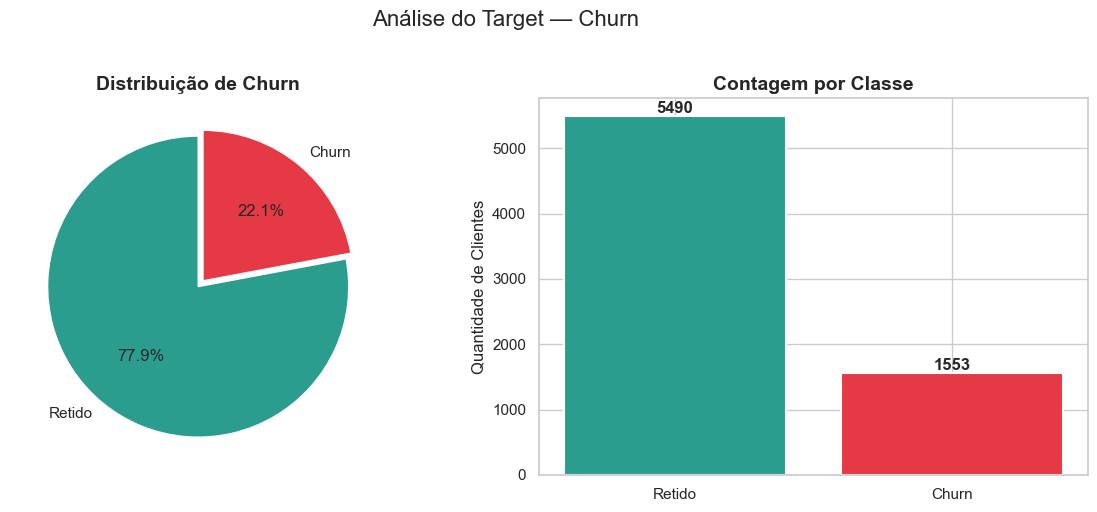

In [6]:
# Distribuição do target
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

churn_counts = df['churn'].value_counts()
axes[0].pie(churn_counts, labels=['Retido', 'Churn'],
            colors=['#2A9D8F', '#E63946'], autopct='%1.1f%%',
            startangle=90, explode=(0, 0.05))
axes[0].set_title('Distribuição de Churn', fontsize=14, fontweight='bold')

axes[1].bar(['Retido', 'Churn'], churn_counts.values,
            color=['#2A9D8F', '#E63946'], edgecolor='white', linewidth=1.5)
axes[1].set_title('Contagem por Classe', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Quantidade de Clientes')
for i, v in enumerate(churn_counts.values):
    axes[1].text(i, v + 50, str(v), ha='center', fontweight='bold')

plt.suptitle('Análise do Target — Churn', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

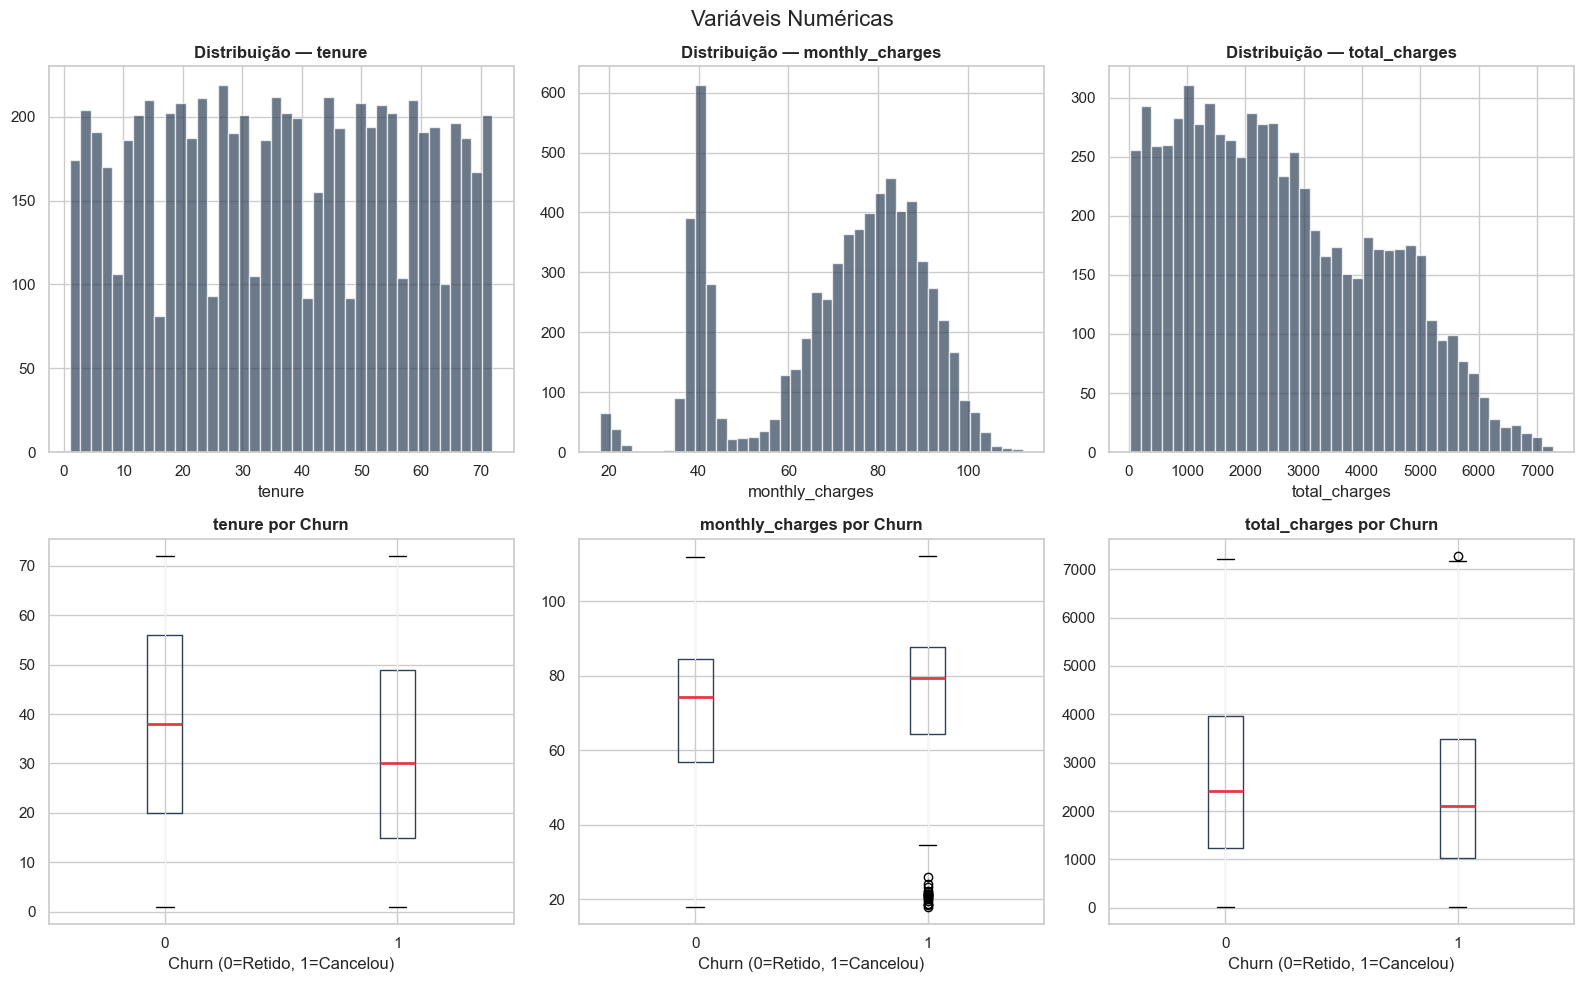

In [7]:
# Distribuição de variáveis numéricas
num_cols = ['tenure', 'monthly_charges', 'total_charges']
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for i, col in enumerate(num_cols):
    # Histograma
    axes[0, i].hist(df[col], bins=40, color='#2E4057', alpha=0.7, edgecolor='white')
    axes[0, i].set_title(f'Distribuição — {col}', fontweight='bold')
    axes[0, i].set_xlabel(col)
    
    # Boxplot por churn
    df.boxplot(column=col, by='churn', ax=axes[1, i],
               boxprops=dict(color='#2E4057'),
               medianprops=dict(color='#E63946', linewidth=2))
    axes[1, i].set_title(f'{col} por Churn', fontweight='bold')
    axes[1, i].set_xlabel('Churn (0=Retido, 1=Cancelou)')

plt.suptitle('Variáveis Numéricas', fontsize=16)
plt.tight_layout()
plt.show()

## 3. Análise Bivariada — Features vs Churn

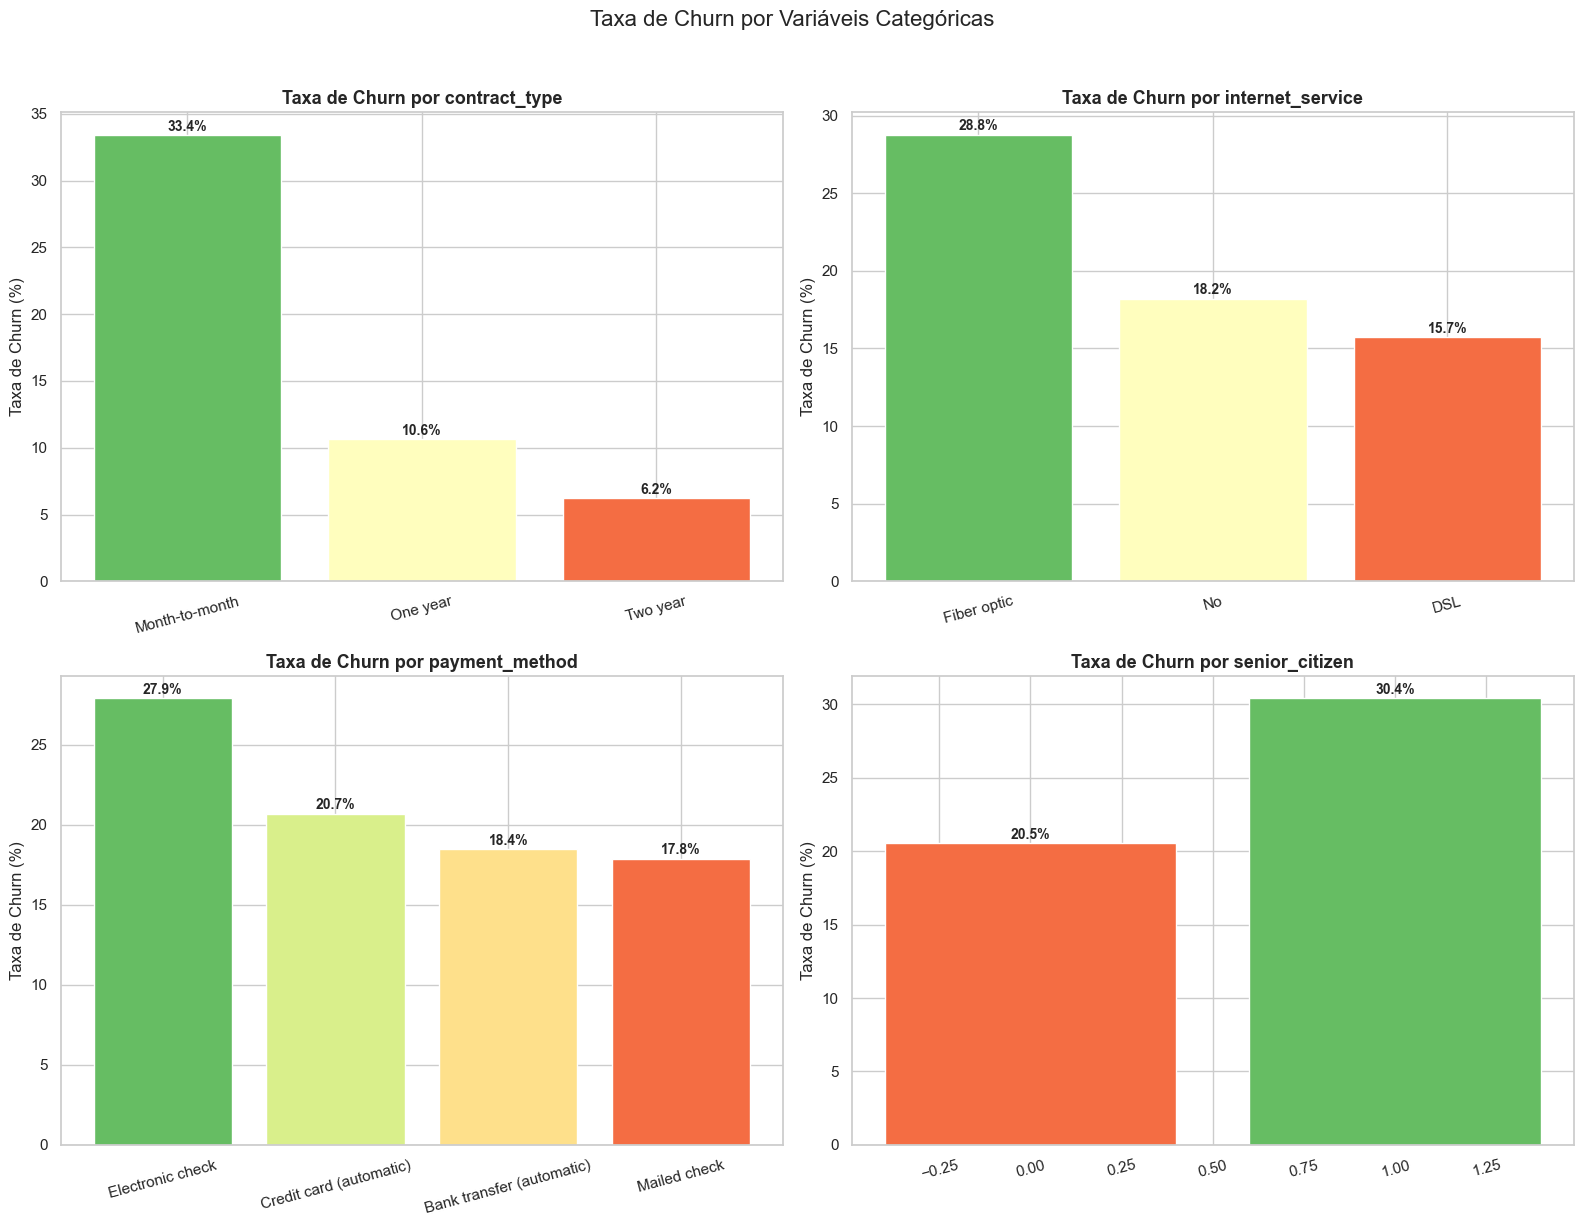

In [8]:
# Taxa de churn por variável categórica
cat_cols = ['contract_type', 'internet_service', 'payment_method', 'senior_citizen']
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

for ax, col in zip(axes.flatten(), cat_cols):
    churn_rate = df.groupby(col)['churn'].mean().sort_values(ascending=False)
    colors = plt.cm.RdYlGn_r(np.linspace(0.2, 0.8, len(churn_rate)))
    bars = ax.bar(churn_rate.index, churn_rate.values * 100, color=colors, edgecolor='white')
    ax.set_title(f'Taxa de Churn por {col}', fontsize=13, fontweight='bold')
    ax.set_ylabel('Taxa de Churn (%)')
    ax.tick_params(axis='x', rotation=15)
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.3,
                f'{h:.1f}%', ha='center', fontweight='bold', fontsize=10)

plt.suptitle('Taxa de Churn por Variáveis Categóricas', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

## 4. Matriz de Correlação

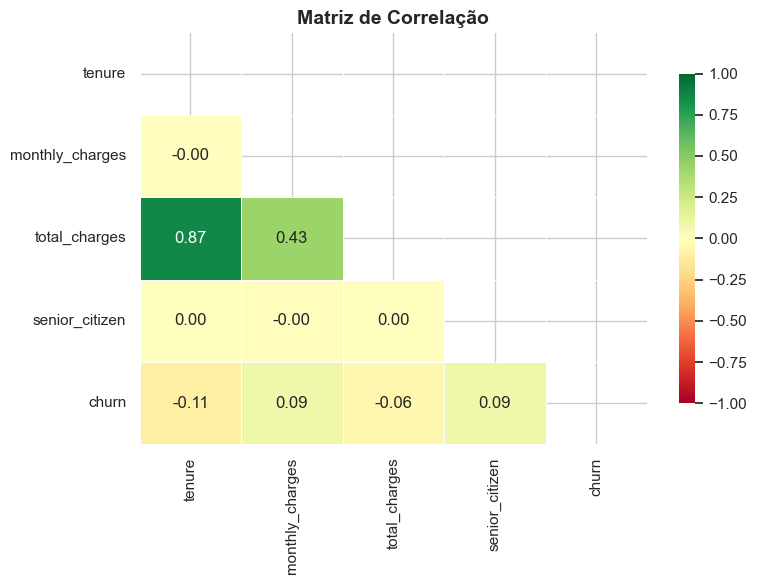

In [9]:
# Correlação entre variáveis numéricas e churn
num_df = df[['tenure', 'monthly_charges', 'total_charges', 'senior_citizen', 'churn']]
corr = num_df.corr()

plt.figure(figsize=(8, 6))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdYlGn',
            center=0, vmin=-1, vmax=1, linewidths=0.5,
            cbar_kws={'shrink': 0.8})
plt.title('Matriz de Correlação', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Insights e Conclusões

### 🔍 Principais descobertas:

1. **Taxa de churn:** ~22% dos clientes cancelaram — dataset desbalanceado, exige SMOTE
2. **Contrato:** Clientes Month-to-month têm churn muito maior que contratos anuais/bianuais
3. **Internet:** Fibra ótica tem maior churn — possível insatisfação com qualidade ou preço
4. **Tenure:** Clientes mais novos (< 12 meses) têm maior propensão ao churn
5. **Cobrança:** Clientes com monthly_charges mais alto tendem a churnar mais
6. **Pagamento:** Electronic check correlaciona com maior churn

### ➡️ Próximos passos:
- Notebook 02: Feature Engineering baseado nestes insights
- Criar variáveis derivadas (avg_charges, tenure_group, etc.)
- Tratar desbalanceamento com SMOTE